# Written by : Pouya Belali

# **First Question**

---



In [384]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

Heuristic 1: O(n) - Number of unsorted rows

---

In [385]:
def heuristic_1(state):
    n = state.shape[0]  # Grid size
    count = 0
    for row in state:
        if not np.all(row == np.sort(row)):  # Check if the row is sorted
            count += 1
    return count

Heuristic 2: O(n^2) - Total Manhattan distance

---



In [386]:
def heuristic_2(state):
    n = state.shape[0]  # Grid size
    total_distance = 0
    for value in range(1, n * n + 1):  # Loop through all values in the grid
        current_position = np.argwhere(state == value)[0]  # Find current position
        target_position = np.array([(value - 1) // n, (value - 1) % n])  # Calculate target position
        total_distance += np.abs(current_position - target_position).sum()  # Add Manhattan distance
    return total_distance

Generate all possible moves by shifting rows and columns

---



In [387]:
def generate_moves(state):
    n = state.shape[0]  # Grid size
    moves = []
    # Shift rows
    for row in range(n):
        for shift in range(1, n):  # Shift by 1 to n-1 positions
            new_state = np.copy(state)
            new_state[row] = np.roll(new_state[row], shift)  # Cyclic shift
            moves.append(new_state)
    # Shift columns
    for col in range(n):
        for shift in range(1, n):  # Shift by 1 to n-1 positions
            new_state = np.copy(state)
            new_state[:, col] = np.roll(new_state[:, col], shift)  # Cyclic shift
            moves.append(new_state)
    return moves

Solve using BFS with Heuristics

---



In [388]:
def bfs_with_heuristics(initial_state, heuristic_function):
    n = initial_state.shape[0]  # Grid size
    goal_state = np.arange(1, n * n + 1).reshape(n, n)  # Goal state (sorted grid)

    # Priority queue for BFS (state, depth, heuristic value)
    queue = deque([(initial_state, 0, heuristic_function(initial_state))])
    visited = set()  # Keep track of visited states

    while queue:
        # Sort queue by heuristic value (smallest depth + heuristic first)
        queue = deque(sorted(queue, key=lambda x: x[1] + x[2]))

        # Get the state with the smallest depth + heuristic
        current_state, depth, _ = queue.popleft()
        if not np.array_equal(current_state, initial_state):
            print(f"Perform move -> \n{current_state}")

        state_tuple = tuple(map(tuple, current_state))  # Convert state to a hashable format

        # Check if goal is reached
        if np.array_equal(current_state, goal_state):
            print(f"Final state -> \n{current_state}")
            return depth  # Return the minimum number of moves

        # Skip already visited states
        if state_tuple in visited:
            continue
        visited.add(state_tuple)  # Mark current state as visited

        # Generate and process all possible moves
        for move in generate_moves(current_state):
            move_tuple = tuple(map(tuple, move))
            if move_tuple not in visited:
                heuristic_value = heuristic_function(move)
                queue.append((move, depth + 1, heuristic_value))  # Add to queue with updated depth

    return -1  # Return -1 if no solution is found (should not happen for this problem)

Input the grid

---



In [389]:
initial_state = np.array([[3, 1, 9], [4, 5, 2], [7, 8, 6]])

Solve using both heuristics


---



In [390]:
print("Initial State:")
print(initial_state)

print("\nUsing Heuristic 1 (O(n) distinct values):")
result_heuristic_1 = bfs_with_heuristics(initial_state, heuristic_1)
print("Minimum Moves:", result_heuristic_1)

print("\nUsing Heuristic 2 (O(n^2) distinct values):")
result_heuristic_2 = bfs_with_heuristics(initial_state, heuristic_2)
print("Minimum Moves:", result_heuristic_2)

Initial State:
[[3 1 9]
 [4 5 2]
 [7 8 6]]

Using Heuristic 1 (O(n) distinct values):
Perform move -> 
[[3 1 2]
 [4 5 6]
 [7 8 9]]
Perform move -> 
[[1 2 3]
 [4 5 6]
 [7 8 9]]
Final state -> 
[[1 2 3]
 [4 5 6]
 [7 8 9]]
Minimum Moves: 2

Using Heuristic 2 (O(n^2) distinct values):
Perform move -> 
[[3 1 2]
 [4 5 6]
 [7 8 9]]
Perform move -> 
[[1 2 3]
 [4 5 6]
 [7 8 9]]
Final state -> 
[[1 2 3]
 [4 5 6]
 [7 8 9]]
Minimum Moves: 2


#**Second Question**

---





Parameters for the Genetic Algorithm

---



In [391]:
TARGET_Y = 1  # Target value for y
X = np.array([4, -2, 3.5, 5])  # Input coefficients
POPULATION_SIZE = 50  # Adjusted population size
GENERATIONS = 100  # Increased number of generations
INITIAL_MUTATION_RATE = 0.15  # Adjustable mutation rate
MUTATION_DECAY = 0.95  # Gradually reduce mutation rate
BOUNDS = [-10, 10]  # Bounds for weights (w values)

Initialize the population with random values

---



In [392]:
def initialize_population(size, dimensions):
    return np.random.uniform(BOUNDS[0], BOUNDS[1], (size, dimensions))

Error calculation using absolute difference instead of squared error

---



In [393]:
def fitness_function(weights):
    y = np.dot(weights, X)
    return abs(TARGET_Y - y)  # Absolute error

Selection: Weighted selection based on inverse error

---



In [394]:
def select_parents(population, fitness):
    fitness_adjusted = 1 / (fitness + 1e-6)
    probabilities = fitness_adjusted / fitness_adjusted.sum()
    parent_indices = np.random.choice(len(population), size=2, p=probabilities)
    return population[parent_indices[0]], population[parent_indices[1]]

Crossover: Single-point crossover with a twist

---



In [395]:
def crossover(parent1, parent2):
    point = np.random.randint(0, len(parent1))  # Allow crossover at index 0
    child1 = np.concatenate((parent1[:point], parent2[point:]))
    child2 = np.concatenate((parent2[:point], parent1[point:]))
    return child1, child2

Mutation: Apply multiple mutations with dynamic probability

---



In [396]:
def mutate(individual, mutation_rate):
    for i in range(len(individual)):
        if np.random.rand() < mutation_rate:
            individual[i] += np.random.uniform(-0.5, 0.5)  # Random change in the weight
            individual[i] = np.clip(individual[i], BOUNDS[0], BOUNDS[1])  # Clip to stay within bounds
    return individual

Genetic Algorithm Execution

---



In [397]:
def genetic_algorithm():
    population = initialize_population(POPULATION_SIZE, len(X))
    mutation_rate = INITIAL_MUTATION_RATE
    for generation in range(GENERATIONS):
        # Evaluate calculated y for the population
        calculated_y = np.array([np.dot(ind, X) for ind in population])

        # Filter out individuals with y > 1
        valid_indices = np.where(calculated_y <= 1)[0]
        population = population[valid_indices]

        # Calculate fitness for the filtered population
        fitness = np.array([fitness_function(ind) for ind in population])

        fitness = np.array([fitness_function(ind) for ind in population])
        new_population = []
        while len(new_population) < POPULATION_SIZE:
            # Select parents
            parent1, parent2 = select_parents(population, fitness)
            # Crossover to produce offspring
            child1, child2 = crossover(parent1, parent2)
            # Apply mutations
            child1 = mutate(child1, mutation_rate)
            child2 = mutate(child2, mutation_rate)
            new_population.extend([child1, child2])
        population = np.array(new_population[:POPULATION_SIZE])
        mutation_rate *= MUTATION_DECAY  # Reduce mutation rate over time

    # Find and return the best solution
    fitness = np.array([fitness_function(ind) for ind in population])
    best_index = np.argmin(fitness)
    return population[best_index], np.dot(population[best_index], X)


Run the Genetic Algorithm And Store The First 100 Results

---



In [398]:
results = []
for i in range(100):
    optimal_weights, calculated_y = genetic_algorithm()
    results.append((optimal_weights, calculated_y))

Display Results In A Dataframe

---

In [402]:
df = pd.DataFrame(results, columns=['Optimal Weights (W)', 'Calculated y'])
df['Target y'] = TARGET_Y  # Add a column for the target value

# Convert all feature columns to strings
for col in df.columns:
    df[col] = df[col].astype(str)

calculated_y_values = df['Calculated y'].astype(float)

# Find the maximum
max_calculated_y = calculated_y_values.max()
print(f"The biggest calculated y is: {max_calculated_y}")

# Calculate and print the average
average_calculated_y = calculated_y_values.mean()
print(f"The average calculated y is: {average_calculated_y}")

# Display The Dataframe
display(pd.concat([df.head(10), df.tail(10)]))

The biggest calculated y is: 0.9999478895844476
The average calculated y is: 0.9924414932989043


,Optimal Weights (W),Calculated y,Target y
0,[ 1.50437647 -0.22985789 -5.04343582 2.43443906],0.9973916011829296,1
1,[-0.2143531 8.08488319 1.2012881 2.76342837],0.9944714101186012,1
2,[-4.09181616 -3.08468581 7.31153093 -2.87850922],0.9999191218084498,1
3,[-2.44734988 0.60347615 -6.64743656 7.04913145],0.9832774639940851,1
4,[ 8.15060723 3.33590645 -8.34223319 0.85157555],0.9906775739461624,1
5,[ 0.19250305 -9.75618561 0.80572269 -4.42238508],0.9904874391300602,1
6,[-3.79549092 2.01794896 7.1955171 -0.9935758 ],0.9985692292166046,1
7,[-2.77231518 -7.3477413 2.44558631 -2.23323882],0.999579871923034,1
8,[ 5.55176861 4.5904981 -0.88371576 -1.78750085],0.995568828921769,1
9,[-3.31472335 -4.31064463 2.24955647 -0.44847579],0.9934645813536092,1


Display Results In A Plot

---



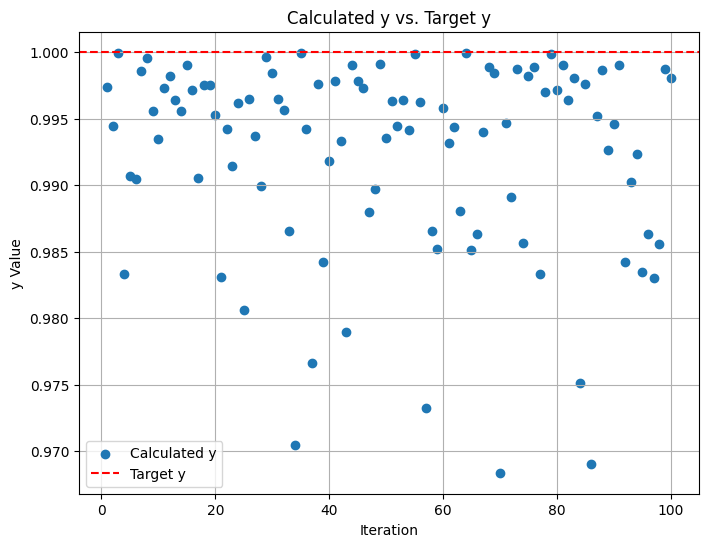

In [400]:
# Extract the data for plotting
calculated_y_values = df['Calculated y'].astype(float)  # Convert to numeric

# Create the scatter plot
plt.figure(figsize=(8, 6))  # Adjust figure size if needed
plt.scatter(range(1, len(calculated_y_values) + 1), calculated_y_values, marker='o', label='Calculated y')
plt.axhline(y=TARGET_Y, color='r', linestyle='--', label='Target y')  # Add a horizontal line for the target value

# Customize the plot
plt.title('Calculated y vs. Target y')
plt.xlabel('Iteration')
plt.ylabel('y Value')
plt.legend()
plt.grid(True)
plt.show()